# Monte Carlo: estimating $\pi$, ellipse area, and integrals

**Course Assignments / Quizzes | Mathematical Methods for Physicists II**


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Fix the pseudorandom stream for reproducibility; do not reseed inside the trial loops.
np.random.seed(23)


## 1. Estimate $\pi$ with a square and a circle

**Task.** Draw points inside $-1\leq x,y<1$ and count how many lie within $x^2+y^2\leq1$. The unit circle occupies fraction $\pi/4$ of the enclosing square, so

$$\widehat\pi=4\frac{N_{\rm inside}}{N}.$$

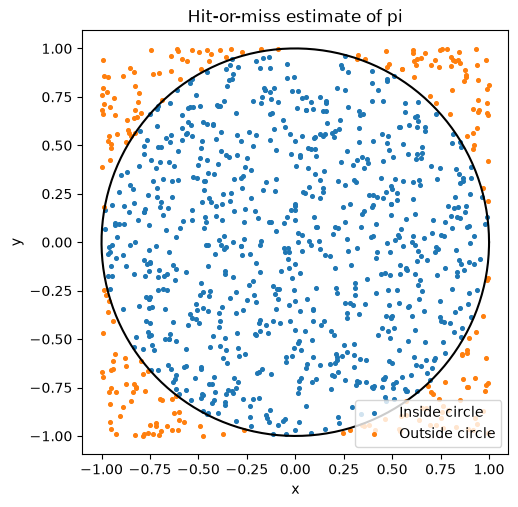

Estimate from the plotted points: 3.092


In [10]:
def estimate_pi(number):
    # Sample a uniform fine grid in the enclosing square, not a continuous distribution.
    # Its hit fraction approximates the area fraction; finite grid spacing adds a small bias.
    x = np.random.randint(-1000, 1000, size=number)/1000
    y = np.random.randint(-1000, 1000, size=number)/1000
    
    # Each Boolean is a Bernoulli hit: True contributes 1, False contributes 0.
    inside = x**2 + y**2 <= 1
    
    # Square area is 4 and circle area is pi, hence pi_hat = 4 * hit fraction.
    estimate = 4*np.sum(inside)/number
    
    return estimate

# Show what is being counted using a small sample.
number = 1000
x = np.random.randint(-1000, 1000, size=number)/1000
y = np.random.randint(-1000, 1000, size=number)/1000
inside = x**2 + y**2 <= 1

plt.figure(figsize=(5.5, 5.5))
plt.scatter(x[inside], y[inside], s=7, label='Inside circle')
plt.scatter(x[~inside], y[~inside], s=7, label='Outside circle')
angle = np.linspace(0, 2*np.pi, 300)
plt.plot(np.cos(angle), np.sin(angle), color='black')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Hit-or-miss estimate of pi')
plt.axis('equal')
plt.legend()
plt.show()

print('Estimate from the plotted points:', round(4*np.sum(inside)/number, 5))


### Reading the hit-or-miss picture

Points are sampled throughout the square, including the corners outside the circle. The fraction classified inside estimates the circle-to-square area ratio; multiplying by four estimates pi. This particular scatter plot is one random realization, not an accuracy guarantee.

The sampler uses integer coordinates divided by 1000, so points lie on a fine grid. Its expected hit fraction is the fraction of grid sites inside the circle, only approximately the continuous area fraction. This small discretization bias does not disappear by increasing the number of draws while keeping the grid fixed. The current sample sizes are intended to illustrate sampling fluctuations; continuous uniform coordinates would remove this particular grid approximation.


## 2. Change the number of sampled points

N = 100 | pi estimate = 3.2
N = 500 | pi estimate = 3.056
N = 1000 | pi estimate = 3.08
N = 5000 | pi estimate = 3.1328
N = 10000 | pi estimate = 3.1652
N = 50000 | pi estimate = 3.13
N = 100000 | pi estimate = 3.14664
N = 200000 | pi estimate = 3.14436
N = 270000 | pi estimate = 3.14587
N = 100000 | pi estimate = 3.13676
N = 400000 | pi estimate = 3.14503
N = 500000 | pi estimate = 3.14364
N = 550000 | pi estimate = 3.13948


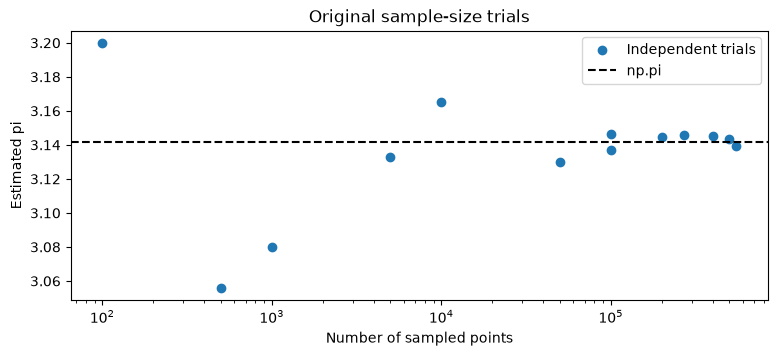

In [11]:
trial_sizes = [100, 500, 1000, 5000, 10000, 50000, 100000,
               200000, 270000, 100000, 400000, 500000, 550000]
trial_estimates = []

# Draw a fresh sample at every N; these are not prefixes of one growing sample.
for number in trial_sizes:
    estimate = estimate_pi(number)
    trial_estimates.append(estimate)
    print('N =', number, '| pi estimate =', round(estimate, 5))

plt.figure(figsize=(9, 3.5))
plt.scatter(trial_sizes, trial_estimates, label='Independent trials')
plt.axhline(np.pi, color='black', linestyle='--', label='np.pi')
plt.xscale('log')
plt.xlabel('Number of sampled points')
plt.ylabel('Estimated pi')
plt.title('Original sample-size trials')
plt.legend()
plt.show()


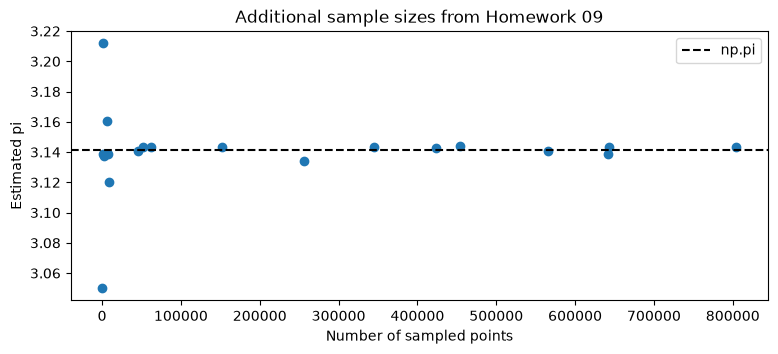

In [12]:
irregular_sizes = [320, 670, 6040, 9200, 45000, 62000, 423000,
                   565000, 642000, 454000, 345000, 804600, 152000,
                   1050, 8000, 643456, 52134, 2653, 256569]
irregular_estimates = []

for number in irregular_sizes:
    irregular_estimates.append(estimate_pi(number))

plt.figure(figsize=(9, 3.5))
plt.scatter(irregular_sizes, irregular_estimates)
plt.axhline(np.pi, color='black', linestyle='--', label='np.pi')
plt.xlabel('Number of sampled points')
plt.ylabel('Estimated pi')
plt.title('Additional sample sizes from Homework 09')
plt.legend()
plt.show()


### Reading the sample-size comparisons

Each point is a fresh trial, so a larger sample can occasionally be farther from pi than a smaller one. The statistical claim concerns the **typical spread**, which decreases approximately as $N^{-1/2}$, not monotonic improvement in every realization. Repeated sample sizes represent separate trials, not duplicated results. The later RMS-error experiment averages over repeated runs to make this trend easier to assess.


A larger $N$ generally makes the **typical error** smaller. 

## 3. Repeat the same experiment 50 times

**Task:** Produce 50 separate estimates, each based on 10,000 random points. Calculate their mean and sample variance. We also report standard deviation and standard error of the **50-run mean**, since variance itself does not have the same units as an error in $\pi$.


Mean of 50 estimates: 3.14157
Sample variance of estimates: 0.0002208
Standard deviation of one estimate: 0.01486
Standard error of the 50-run mean: 0.0021
Reference pi: 3.14159


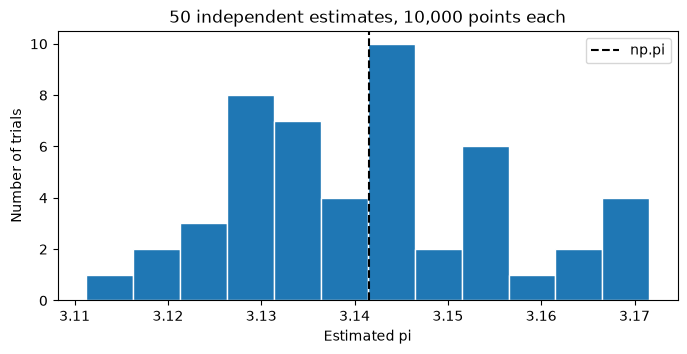

In [13]:
repeats = 50
pi_values = []

# Independent batches reveal the sampling distribution of an N=10000 estimate.
for trial in range(repeats):
    pi_values.append(estimate_pi(10000))

mean_pi = np.mean(pi_values)

# ddof=1 divides by repeats-1 to estimate the variance of individual run estimates.
variance_pi = np.var(pi_values, ddof=1)
std_pi = np.sqrt(variance_pi)

# The uncertainty of the average of 50 independent runs is smaller than one-run spread.
se_mean = std_pi/np.sqrt(repeats)

print('Mean of 50 estimates:', round(mean_pi, 5))
print('Sample variance of estimates:', round(variance_pi, 7))
print('Standard deviation of one estimate:', round(std_pi, 5))
print('Standard error of the 50-run mean:', round(se_mean, 5))
print('Reference pi:', round(np.pi, 5))

plt.figure(figsize=(8, 3.5))
plt.hist(pi_values, bins=12, edgecolor='white')
plt.axvline(np.pi, color='black', linestyle='--', label='np.pi')
plt.xlabel('Estimated pi')
plt.ylabel('Number of trials')
plt.title('50 independent estimates, 10,000 points each')
plt.legend()
plt.show()


### Reading the distribution of repeated estimates

The histogram shows the spread of individual 10,000-point estimates across 50 trials. That spread is measured by their sample standard deviation. The standard error printed for the 50-run mean is smaller by a factor of (sqrt{50}): it describes uncertainty in the average, not the width of this histogram.

A roughly bell-shaped distribution is expected for large independent hit counts, but 50 runs give a noisy histogram. The reference line need not pass through its tallest bin. Standard error describes sampling uncertainty and does not include the fine-grid bias discussed above.


## 4. Estimate the area of an ellipse in two ways

**Task:** The ellipse $x^2/2^2+y^2=1$ lies inside the rectangle $-2\leq x<2$, $-1\leq y<1$, whose area is 8. Count hits inside the ellipse to obtain

$$\widehat A_{\rm direct}=8\frac{N_{\rm inside}}{N}.$$

The second approach estimates $\pi$ with a unit circle and uses $A=ab\pi=2\pi$. The exact geometric benchmark is $A=2\pi$. Run **50 estimates with 50,000 points each** for both approaches.


Direct ellipse hits
  Mean area: 6.27999
  Sample variance: 0.000222
  Standard deviation: 0.0149
  Standard error of mean: 0.00211
Area from estimated pi
  Mean area: 6.28388
  Sample variance: 0.0002279
  Standard deviation: 0.0151
  Standard error of mean: 0.00214
Exact area 2*pi: 6.28319


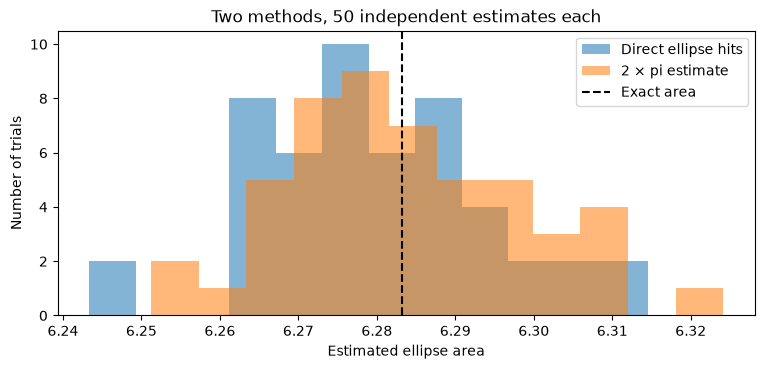

In [14]:
def ellipse_direct(number):
    x = np.random.randint(-2000, 2000, size=number)/1000
    y = np.random.randint(-1000, 1000, size=number)/1000
    
    # Ellipse test: x**2/4 + y**2 <= 1, equivalent to x**2 + 4*y**2 <= 4.
    inside = x**2 + 4*y**2 <= 4
    
    # Multiply hit probability by enclosing rectangle area 4*2=8.
    return 8*np.sum(inside)/number

def ellipse_from_pi(number):
    # With semiaxes a=2, b=1, area is a*b*pi; propagate the random pi estimate.
    return 2*estimate_pi(number)

direct_values = []
pi_method_values = []

# Use separate random batches for the direct and rescaled-circle estimates.
for trial in range(50):
    direct_values.append(ellipse_direct(50000))
    pi_method_values.append(ellipse_from_pi(50000))

for name, values in [('Direct ellipse hits', direct_values), ('Area from estimated pi', pi_method_values)]:
    print(name)
    print('  Mean area:', round(np.mean(values), 5))
    print('  Sample variance:', round(np.var(values, ddof=1), 7))
    print('  Standard deviation:', round(np.std(values, ddof=1), 5))
    print('  Standard error of mean:', round(np.std(values, ddof=1)/np.sqrt(50), 5))

print('Exact area 2*pi:', round(2*np.pi, 5))

plt.figure(figsize=(9, 3.7))
plt.hist(direct_values, bins=12, alpha=0.55, label='Direct ellipse hits')
plt.hist(pi_method_values, bins=12, alpha=0.55, label='2 × pi estimate')
plt.axvline(2*np.pi, color='black', linestyle='--', label='Exact area')
plt.xlabel('Estimated ellipse area')
plt.ylabel('Number of trials')
plt.title('Two methods, 50 independent estimates each')
plt.legend()
plt.show()


The two estimators are the same hit-or-miss geometry after rescaling $x$ by 2.


### Comparing the two ellipse estimators

For continuous uniform samples, scaling the unit-circle coordinates by the semiaxes gives the direct ellipse experiment. Both methods then have the same theoretical hit probability and estimator variance at the same N. Their two histograms need not coincide because they use different random batches; a difference between the displayed means is not evidence that one method is intrinsically better.

Here the integer-grid implementations have slightly different normalized x spacings after rescaling. Consequently their exact discrete hit probabilities can differ slightly, even though they approximate the same continuous area (2pi). Neither repetition nor a smaller standard error of the mean removes a fixed discretization bias.



## 5. Monte Carlo integration

**Task.** Sample $x$ uniformly from $[a,b]$ and estimate the integral of $ \rm sin (100 x) $ using

$$\widehat I=(b-a)\frac{1}{N}\sum_{i=1}^{N} f(x_i).$$

In [15]:
def mc_integral(start, end, runs, which_function):
    # Uniform sampling turns the integral into interval width times E[f(X)].
    x = np.random.uniform(start, end, size=runs)
    if which_function == 1:
        values = np.sin(100*x)
    elif which_function == 2:
        # Absolute value makes the base nonnegative for the noninteger exponent x.
        values = np.abs(np.sin(100*x))**x
    else:
        raise ValueError('Choose function 1 or 2')
    estimate = (end-start)*np.mean(values)
    # Independent f(X) values give SE = width * sample SD / sqrt(N).
    # This measures sampling fluctuations, not a guaranteed bound on the actual error.
    return estimate, (end-start)*np.std(values, ddof=1)/np.sqrt(runs)

first, first_se = mc_integral(0, 2*np.pi, 100000, 1)
second, second_se = mc_integral(0, 2*np.pi, 1000, 2)
print('Integral of sin(100x):', round(first, 5), '| estimated standard error:', round(first_se, 5))
print('Exact integral of sin(100x): 0')


Integral of sin(100x): 0.00373 | estimated standard error: 0.01404
Exact integral of sin(100x): 0


### Interpreting the oscillatory integral

Over (0le xle2pi), (sin(100x)) completes 100 cycles, and its exact signed integral is zero. The Monte Carlo estimate fluctuates around zero because a finite random sample does not balance positive and negative values perfectly. Integrating the signed sine is different from calculating the area under its absolute value.

The reported standard error estimates the typical sampling fluctuation, not a strict error bound. For this sine, the uniform-sample variance is (1/2), giving a theoretical standard error (2pi/sqrt{2N}), about 0.0140 for (N=100000). The function also evaluates the separate nonnegative integrand (|sin(100x)|^x); the displayed zero benchmark applies only to the signed-sine result, not that second calculation.


## 6. How does typical error change with $N$?

**Task:** At each sample size, repeat the $\pi$ estimate 30 times and measure its root-mean-square (RMS) error. For independent random samples the expected size of fluctuations falls approximately as $1/\sqrt{N}$. This averaged comparison is more informative than demanding that any one estimate always improve.


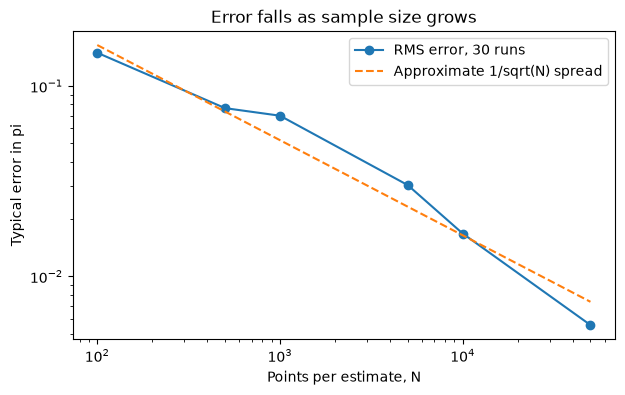

In [16]:
sizes = [100, 500, 1000, 5000, 10000, 50000]
rms_error = []

for number in sizes:
    squared_errors = []
    
    # Repetitions estimate typical squared error, rather than one lucky/unlucky result.
    for trial in range(30):
        result = estimate_pi(number)
        squared_errors.append((result-np.pi)**2)
    
    # RMS error includes both sampling variance and any systematic bias.
    rms_error.append(np.sqrt(np.mean(squared_errors)))

theory = []

for number in sizes:
    # Continuous-square benchmark: Var(4*hit_fraction)=16*p*(1-p)/N.
    probability_inside = np.pi/4
    theory.append(4*np.sqrt(probability_inside*(1-probability_inside)/number))

plt.figure(figsize=(7, 4))
plt.loglog(sizes, rms_error, 'o-', label='RMS error, 30 runs')
plt.loglog(sizes, theory, '--', label='Approximate 1/sqrt(N) spread')
plt.xlabel('Points per estimate, N')
plt.ylabel('Typical error in pi')
plt.title('Error falls as sample size grows')
plt.legend()
plt.show()


### Reading the RMS-error plot

The measured RMS error combines 30 independent trials at each $N$. The dashed curve is the continuous-geometry Bernoulli prediction $4 \sqrt{p(1-p)/N}$, with (p=$\pi$/4). On log–log axes its slope is (-1/2): reducing typical sampling error by a factor of ten requires about 100 times as many points.

The measured curve can fluctuate around this prediction because 30 trials give only a finite estimate of RMS error. At sufficiently large $N$, a fixed-grid bias would produce an error floor; the dashed sampling-spread curve does not include that bias. Do not infer a failure of Monte Carlo from one small departure from the line.


## Conclusions

The circle and ellipse exercises estimate an area from the fraction of points that land inside a shape. Repeated trials show the distinction between one result, the spread of results, and the uncertainty of their average. Monte Carlo integration uses the same sampling idea for functions rather than geometric hits. Increasing $N$ reduces *typical* error, approximately as $N^{-1/2}$, without guaranteeing that each new estimate is closer to the answer.